# Linked Gaussian Process

x -> w -> y when we know w

Before working on linked GP, trying step function with GP first


In [ ]:
# Import library
import numpy as np
from matplotlib import pyplot as plt
import math
from scipy.special import kv

def squared_exponential(x1, x2, length_scale, sigma):
    return sigma**2 * np.exp((-(x1-x2)**2)/(2*length_scale**2))

def matern(x1, x2, length_scale, nu):
    term1 = (2**(1-nu)) / math.gamma(nu)
    term2 = (np.sqrt(2*nu) * np.abs(x1-x2) / length_scale)**nu
    r = np.sqrt(2*nu) * np.abs(x1-x2) / length_scale
    if r == 0:
        return 1  # kv(nu, 0) is not defined, but the limit as r -> 0 is 1
    term3 = kv(nu, r)
    return term1 * term2 * term3



In [2]:
x_train = np.linspace(0, 1, 10)
y_train = np.where(x_train < 0.5, 1, -1)

In [3]:
def R(x1, x2, nugget, length_scale=1, sigma=1, nu=1.5, kernel_type='squared_exponential'):
    n = len(x1)
    m = len(x2)
    R_matrix = np.zeros((n, m))
    I = np.zeros((n, m))
    for i in range(n):
        for j in range(m):
            I[i,j] = 1 if i==j else 0
    for i in range(n):
        for j in range(m):
            if kernel_type == 'squared_exponential':
                R_matrix[i][j] = squared_exponential(x1[i], x2[j], length_scale, sigma)
            elif kernel_type == 'matern':
                R_matrix[i][j] = matern(x1[i], x2[j], length_scale, nu)
            else:
                raise ValueError("Invalid kernel type. Choose 'squared_exponential' or 'matern'.")
    return R_matrix + nugget * I

In [4]:
def gp_predict(x_new, x_train, y_train, length_scale, R_inv, sigma = 1, nugget = 1, nu=1.5, kernel_type='squared_exponential'):
    if kernel_type == 'squared_exponential':
        r_x0 = np.array([squared_exponential(x_new, x_i, length_scale, sigma) for x_i in x_train])
    elif kernel_type == 'matern':
        r_x0 = np.array([matern(x_new, x_i, length_scale, nu) for x_i in x_train])
    else:
        raise ValueError("Invalid kernel type. Choose 'squared_exponential' or 'matern'.")
    mean = r_x0.T @ R_inv @ y_train
    variance = sigma**2 * (1 + nugget - r_x0.T @ R_inv @ r_x0)
    return mean, variance

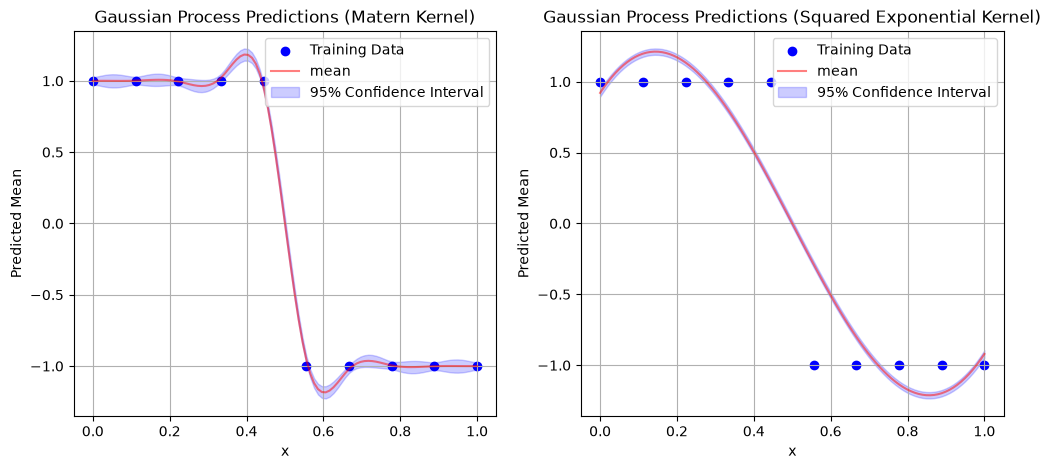

In [5]:
fig, ax = plt.subplots(1,2, figsize=(12, 5))
ax[0].scatter(x_train, y_train, color='blue', label='Training Data')
ax[1].scatter(x_train, y_train, color='blue', label='Training Data')
x_new = np.linspace(0, 1, 100)
mean_list1 = []
variance_list1 = []
mean_list2 = []
variance_list2 = []
R_inv = np.linalg.inv(R(x_train, x_train, nugget=10e-5, length_scale=1, sigma=1, nu=1.5, kernel_type='matern'))
for x in x_new:
    mean, variance = gp_predict(x, x_train, y_train, length_scale=1, R_inv=R_inv, sigma=1, nugget=10e-5, nu=1.5, kernel_type='matern')
    mean_list1.append(mean)
    variance_list1.append(variance)
ax[0].plot(x_new, np.array(mean_list1), color='red', alpha=0.5, label ='mean')
ax[0].fill_between(x_new, np.array(mean_list1) - 1.96 * np.sqrt(np.array(variance_list1)), np.array(mean_list1) + 1.96 * np.sqrt(np.array(variance_list1)), color='blue', alpha=0.2, label='95% Confidence Interval')
ax[0].set_title('Gaussian Process Predictions (Matern Kernel)')
ax[0].set_xlabel('x')
ax[0].set_ylabel('Predicted Mean')
ax[0].legend()
ax[0].grid()
R_inv = np.linalg.inv(R(x_train, x_train, nugget=10e-5, length_scale=1, sigma=1, kernel_type='squared_exponential'))
for x in x_new:
    mean, variance = gp_predict(x, x_train, y_train, length_scale=1, R_inv=R_inv, sigma=1, nugget=10e-5, nu=1.5, kernel_type='squared_exponential')
    mean_list2.append(mean)
    variance_list2.append(variance)
ax[1].plot(x_new, np.array(mean_list2), color='red', alpha=0.5, label ='mean')
ax[1].fill_between(x_new, np.array(mean_list2) - 1.96 * np.sqrt(np.array(variance_list2)), np.array(mean_list2) + 1.96 * np.sqrt(np.array(variance_list2)), color='blue', alpha=0.2, label='95% Confidence Interval')
ax[1].set_title('Gaussian Process Predictions (Squared Exponential Kernel)')
ax[1].set_xlabel('x')
ax[1].set_ylabel('Predicted Mean')
ax[1].legend()
ax[1].grid()
plt.show()

We compare the Matern and Squared Exponenetial Kernel.

## Linked Gaussian Process

In [12]:
np.random.seed(5)
x_train = np.linspace(0, 10, 11)
w_train = np.sin(x_train) * 5 + np.random.normal(0, 0.3, size=11)
y_train = w_train**2 + np.random.normal(0, 0.5, size=11)
print('x_train:', x_train)
print('w_train:', w_train)
print('y_train:', y_train)   

x_train: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
w_train: [ 0.13236825  4.10809388  5.27571849  0.6299724  -3.75112952 -4.31987704
 -1.66984721  3.107442    5.0030722   1.96163144 -3.07793494]
y_train: [-0.0849169  16.69702084 28.13494139 -0.43552904 13.72088319 19.23703313
  3.71705522  8.90060598 25.3531552   3.35769396  9.04525691]


In [47]:
np.random.seed(1)
x_train = np.linspace(0, 10, 15)
w_train = np.sin(x_train) * 4 + np.random.normal(0, 0.2, size=15)
y_train = w_train**2 + np.random.normal(0, 0.3, size=15)

In [48]:
# np.random.seed(5)
# x_train = np.linspace(0, 10, 20)
# w_train = np.where(x_train < 5, 1, -1)
# y_train = w_train + np.random.normal(0, 0.5, size=20)

In [49]:
def I_squared_exponential(w_train, nugget, length_scale=1, sigma=1, mu=0):
    I = np.zeros(len(w_train))
    for i, w_i in enumerate(w_train):
        term1 = np.exp((-(w_i-mu)**2)/(2*(length_scale**2 + sigma**2)))
        term2 = np.sqrt(length_scale**2 /(length_scale**2 + sigma**2))
        I[i] = term1 * term2
    return I

def J_squared_exponential(w_train, nugget, length_scale=1, sigma=1, mu=0):
    J = np.zeros((len(w_train), len(w_train)))
    for i, w_i in enumerate(w_train):
        for j, w_j in enumerate(w_train):
            term1 = np.sqrt(length_scale**2 /(length_scale**2 + 2*sigma**2))
            c = (w_i + w_j) / 2
            term2 = np.exp((-(c-mu)**2)/(length_scale**2 + 2*sigma**2))
            term3 = np.exp((-(w_i-w_j)**2)/(4*(length_scale**2)))
            J[i, j] = term1 * term2 * term3
    return J

def mu_paper(I, R_inv , y):
    return I.T @ R_inv @ y

def var_paper(I, J, R_inv, nugget, sigma, y):
    return y.T @ R_inv @ J @ R_inv @ y - (I.T @ R_inv @ y)**2 + sigma**2 *(1 + nugget - np.trace(R_inv @ J))

1. Gaussian Process
2. Linked Gaussian Process

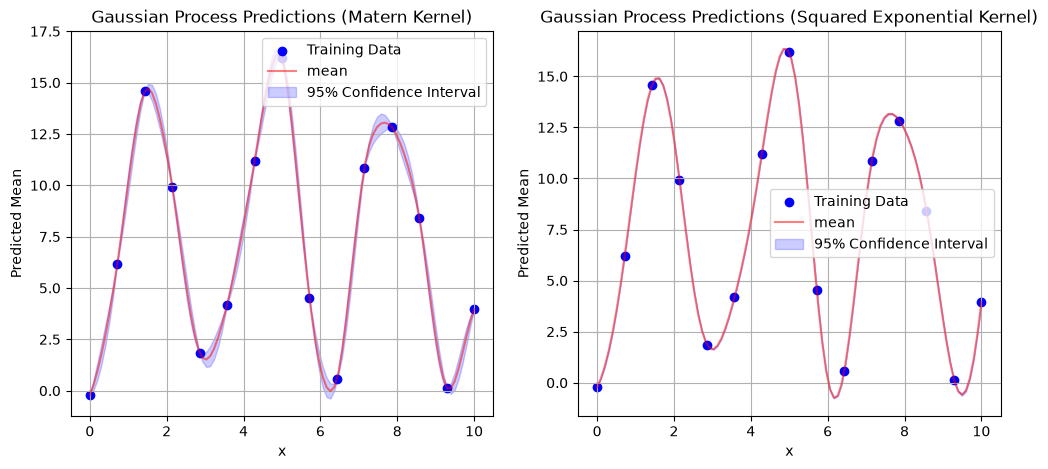

In [50]:
fig, ax = plt.subplots(1,2, figsize=(12, 5))
ax[0].scatter(x_train, y_train, color='blue', label='Training Data')
ax[1].scatter(x_train, y_train, color='blue', label='Training Data')
x_new = np.linspace(0, 10, 100)
mean_list1 = []
variance_list1 = []
mean_list2 = []
variance_list2 = []
R_inv = np.linalg.inv(R(x_train, x_train, nugget=10e-5, length_scale=1, sigma=1, nu=1.5, kernel_type='matern'))
for x in x_new:
    mean, variance = gp_predict(x, x_train, y_train, length_scale=1, R_inv=R_inv, sigma=1, nugget=10e-5, nu=1.5, kernel_type='matern')
    mean_list1.append(mean)
    variance_list1.append(variance)
ax[0].plot(x_new, np.array(mean_list1), color='red', alpha=0.5, label ='mean')
ax[0].fill_between(x_new, np.array(mean_list1) - 1.96 * np.sqrt(np.array(variance_list1)), np.array(mean_list1) + 1.96 * np.sqrt(np.array(variance_list1)), color='blue', alpha=0.2, label='95% Confidence Interval')
ax[0].set_title('Gaussian Process Predictions (Matern Kernel)')
ax[0].set_xlabel('x')
ax[0].set_ylabel('Predicted Mean')
ax[0].legend()
ax[0].grid()
R_inv = np.linalg.inv(R(x_train, x_train, nugget=10e-5, length_scale=1, sigma=1, kernel_type='squared_exponential'))
for x in x_new:
    mean, variance = gp_predict(x, x_train, y_train, length_scale=1, R_inv=R_inv, sigma=1, nugget=10e-5, nu=1.5, kernel_type='squared_exponential')
    mean_list2.append(mean)
    variance_list2.append(variance)
ax[1].plot(x_new, np.array(mean_list2), color='red', alpha=0.5, label ='mean')
ax[1].fill_between(x_new, np.array(mean_list2) - 1.96 * np.sqrt(np.array(variance_list2)), np.array(mean_list2) + 1.96 * np.sqrt(np.array(variance_list2)), color='blue', alpha=0.2, label='95% Confidence Interval')
ax[1].set_title('Gaussian Process Predictions (Squared Exponential Kernel)')
ax[1].set_xlabel('x')
ax[1].set_ylabel('Predicted Mean')
ax[1].legend()
ax[1].grid()
plt.show()

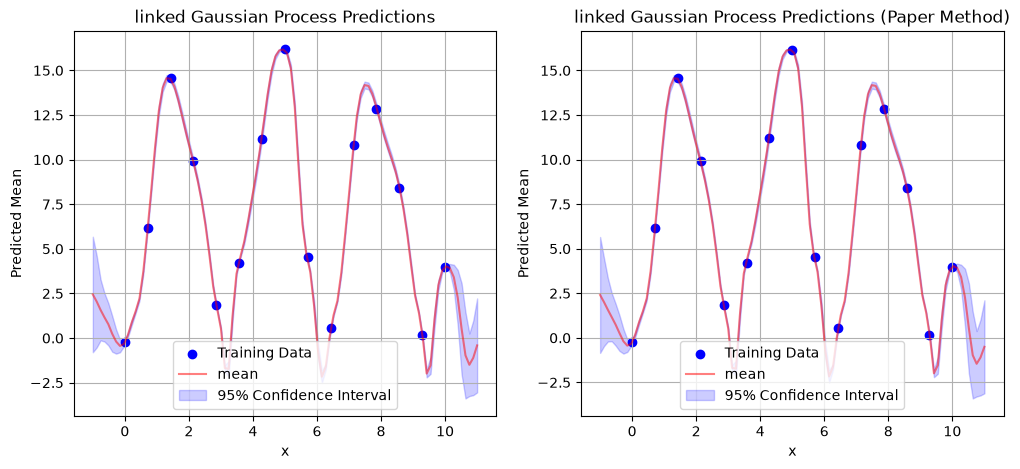

In [51]:
fig, ax = plt.subplots(1,2, figsize=(12, 5))
ax[0].scatter(x_train, y_train, color='blue', label='Training Data')
x_new = np.linspace(-1, 11, 100)
mean1_list = []
variance1_list = []
R_inv_1 = np.linalg.inv(R(x_train, x_train, nugget=10e-5, length_scale=1, sigma=1))
for x in x_new:
    mean, variance = gp_predict(x, x_train, w_train, length_scale=1, R_inv=R_inv_1, sigma=1, nugget=10e-5, kernel_type='squared_exponential')
    mean1_list.append(mean)
    variance1_list.append(variance)
R_inv_2 = np.linalg.inv(R(w_train, w_train, nugget=10e-5, length_scale=1, sigma=1))
mean2_list = []
variance2_list = []
for m, v in zip(mean1_list, variance1_list):
    w_new = np.random.normal(m, np.sqrt(v), size=1000)
    mean2_loop_list = []
    variance2_loop_list = []
    for w in w_new:
        mean, variance = gp_predict(w, w_train, y_train, length_scale=1, R_inv=R_inv_2, sigma=1, nugget=10e-5, kernel_type='squared_exponential')
        mean2_loop_list.append(mean)
        variance2_loop_list.append(variance)
    mean2_list.append(np.mean(mean2_loop_list))
    mean_sq_plus_var = np.array(mean2_loop_list)**2 + np.array(variance2_loop_list)
    term1 = np.mean(mean_sq_plus_var)
    term2 = np.mean(mean2_loop_list)**2
    variance2_list.append(term1 - term2)

ax[0].plot(x_new, np.array(mean2_list), color='red', alpha=0.5, label ='mean')
ax[0].fill_between(x_new, np.array(mean2_list) - 1.96 * np.sqrt(np.array(variance2_list)), np.array(mean2_list) + 1.96 * np.sqrt(np.array(variance2_list)), color='blue', alpha=0.2, label='95% Confidence Interval')
ax[0].set_title('linked Gaussian Process Predictions')
ax[0].set_xlabel('x')
ax[0].set_ylabel('Predicted Mean')
ax[0].legend()
ax[0].grid()

mean_list_paper = []
variance_list_paper = []
for x in x_new:
    mu1, var1 = gp_predict(x, x_train, w_train, length_scale=1, R_inv=R_inv_1, sigma=1, nugget=10e-5, kernel_type='squared_exponential')
    I = I_squared_exponential(w_train, mu=mu1, sigma=np.sqrt(var1), nugget=10e-5)
    J = J_squared_exponential(w_train, mu=mu1, sigma=np.sqrt(var1), nugget=10e-5)
    mean = mu_paper(I, R_inv_2, y_train)
    variance = var_paper(I, J, R_inv_2, nugget=10e-5, sigma=1, y=y_train)
    mean_list_paper.append(mean)
    variance_list_paper.append(variance)

ax[1].scatter(x_train, y_train, color='blue', label='Training Data')
ax[1].plot(x_new, np.array(mean_list_paper), color='red', alpha=0.5, label ='mean')
ax[1].fill_between(x_new, np.array(mean_list_paper) - 1.96 * np.sqrt(np.array(variance_list_paper)), np.array(mean_list_paper) + 1.96 * np.sqrt(np.array(variance_list_paper)), color='blue', alpha=0.2, label='95% Confidence Interval')
ax[1].set_title('linked Gaussian Process Predictions (Paper Method)')
ax[1].set_xlabel('x')
ax[1].set_ylabel('Predicted Mean')
ax[1].legend()
ax[1].grid()

plt.show()

Try `dgpsi`

In [57]:
from dgpsi import kernel, gp, container, combine, lgp

np.random.seed(1)
x_train = np.linspace(0, 10, 15).reshape(-1,1)
w_train = (np.sin(x_train.flatten()) * 4 + np.random.normal(0, 0.2, size=15)).reshape(-1,1)
y_train = (w_train.flatten()**2 + np.random.normal(0, 0.3, size=15)).reshape(-1,1)
print(x_train.shape, w_train.shape, y_train.shape)

# --- Stage 1: train GP1 (X -> W) ---
k1 = kernel(length=np.array([1.0]), name='sexp')
gp1 = gp(x_train, w_train, k1)
gp1.train()
struct1 = gp1.export()

# --- Stage 2: train GP2 (W -> Y) ---
k2 = kernel(length=np.array([1.0]), name='sexp')
gp2 = gp(w_train, y_train, k2)
gp2.train()
struct2 = gp2.export()

# --- Wrap each trained GP in a container, specifying how layers connect ---
# layer 1: GP1 takes column 0 of the GLOBAL input (x)
cont1 = container(struct1, local_input_idx=np.array([0]))
# layer 2: GP2 takes output 0 from layer 1 (GP1's output), hence the nested list
cont2 = container(struct2, local_input_idx=[np.array([0])])

# --- Combine into the linked structure and build the linked emulator ---
all_layer = combine([cont1], [cont2])
linked_model = lgp(all_layer, N=200)   # N = imputations; auto-set to 1 for pure GP chains (no hidden layer)

# --- Predict ---
x_new = np.linspace(-1, 11, 100).reshape(-1, 1)
means, variances = linked_model.predict(x_new)

(15, 1) (15, 1) (15, 1)


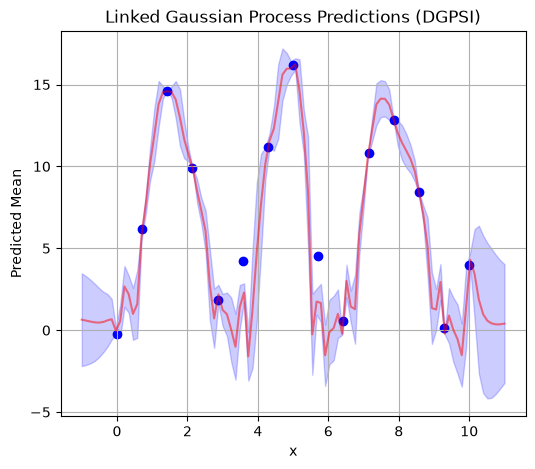

In [68]:
x_new_flat = x_new.flatten()
plt.figure(figsize=(6, 5))
plt.scatter(x_train, y_train, color='blue', label='Training Data')
plt.plot(x_new_flat, means[0].flatten(), color='red', alpha=0.5, label ='mean')
plt.fill_between(x_new_flat, means[0].flatten() - 1.96 * np.sqrt(variances[0].flatten()), means[0].flatten() + 1.96 * np.sqrt(variances[0].flatten()), color='blue', alpha=0.2, label='95% Confidence Interval')       
plt.title('Linked Gaussian Process Predictions (DGPSI)')
plt.xlabel('x')
plt.ylabel('Predicted Mean')
plt.grid()
plt.show()